In [ ]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [ ]:
data

In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

In [ ]:
data

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
# y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:
# X_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv", index= False)
# X_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv", index= False)
# y_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_train.csv", index= False)
# y_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_test.csv", index= False)


In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

In [ ]:
X_test[all_features]

In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv', index=False)
X_test[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [310]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [311]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_train_rF_DEG_train_lung.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_test_rF_DEG_train_lung.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [312]:
import pandas as pd
import mygene

# 2. Extract the Ensembl IDs
# We filter for columns starting with 'ENSG' to avoid messing up index columns like 'Unnamed: 0'
ensembl_ids = [col for col in X_train.columns if col.startswith('ENSG')]

# (Optional) If your IDs have decimals like 'ENSG00000096060.1', you need to strip them:
# ensembl_ids = [col.split('.')[0] for col in ensembl_ids]

# 3. Query the MyGene Database
print("Querying MyGene.info for gene symbols...")
mg = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')

# 4. Create a mapping dictionary { 'ENSG_ID' : 'Gene_Symbol' }
id_to_symbol = {}
for res in results:
    query_id = res['query']
    
    # If a gene symbol is found, use it. Otherwise, keep the original Ensembl ID.
    if 'symbol' in res:
        id_to_symbol[query_id] = res['symbol']
    else:
        id_to_symbol[query_id] = query_id

# 5. Rename the columns in both DataFrames
X_train.rename(columns=id_to_symbol, inplace=True)
X_test.rename(columns=id_to_symbol, inplace=True)

print("Conversion complete!")
print("Preview of new columns in X_train:")
print(X_train.head())

Querying MyGene.info for gene symbols...


5 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267243', 'ENSG00000136653', 'ENSG00000163386', 'ENSG00000148362']


Conversion complete!
Preview of new columns in X_train:
   WDR11-DT    MAGOHB   ZNF542P    IFITM3   HSD17B3     NOMO1   ITGB3BP  \
0  5.590922  4.920421  4.513914  6.808245  3.643703  5.229449  5.296728   
1  7.111388  6.283755  6.129917  4.970461  4.523772  7.441317  7.797965   
2  4.176511  3.782071  2.764579  7.538766  2.764579  3.782071  4.889779   
3  5.002632  4.644839  3.753215  5.804742  2.764579  4.836138  6.369995   
4  6.255441  5.619431  4.050363  7.027353  3.522978  4.234493  6.180337   

   LINC01088    COL6A3  ENSG00000260661  ...   CENATAC     LUC7L      DPP4  \
0   3.774722  5.391791         2.764579  ...  3.485998  4.452266  3.485998   
1   4.749558  3.944942         3.610526  ...  2.764579  3.944942  3.192072   
2   2.764579  4.889779         4.176511  ...  5.344660  6.186679  2.764579   
3   3.753215  4.137808         2.764579  ...  6.427103  7.613563  4.137808   
4   4.050363  5.435232         2.764579  ...  5.367917  5.435232  2.764579   

        LTF      PRCP   

In [4]:
X_test

,WDR11-DT,MAGOHB,ZNF542P,IFITM3,HSD17B3,NOMO1,ITGB3BP,LINC01088,COL6A3,ENSG00000260661,...,CENATAC,LUC7L,DPP4,LTF,PRCP,IL1R2,RRP12,ASGR2,RPS4Y1,TNFRSF10C
0,6.451547,5.348242,5.063048,7.340270,4.175718,5.665411,8.002006,4.625584,5.027229,3.306779,...,4.346157,4.521600,3.711639,2.830723,4.138130,2.830723,2.830723,2.830723,5.742559,2.830723
1,6.630307,5.769564,5.769564,3.921878,4.450995,5.844078,6.824695,4.551511,5.373541,3.728479,...,4.886915,5.026358,3.470567,7.424813,5.026358,3.921878,6.730802,4.644246,2.830723,3.921878
2,4.806340,4.468396,2.830723,7.664287,3.783802,4.345067,4.579964,3.783802,6.068926,2.830723,...,6.057216,6.159271,2.830723,2.830723,4.972535,3.988061,3.783802,6.068926,7.984931,4.579964
3,6.948542,6.390590,5.743158,5.220952,3.531932,6.448757,7.818158,4.996651,4.023021,4.564307,...,3.751771,3.531932,2.830723,4.535230,2.830723,3.328968,4.023021,2.830723,2.830723,3.924027
4,7.263197,6.852681,6.983045,5.905861,4.972501,6.667009,7.623942,4.838434,3.564025,4.543893,...,2.830723,3.401148,2.830723,2.830723,4.221185,3.161482,2.830723,3.401148,5.322133,3.161482
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178,7.793642,7.068577,6.270715,4.704627,5.540731,6.599390,9.150536,4.909011,5.282180,4.881746,...,2.830723,2.830723,2.830723,2.830723,3.223397,2.830723,2.830723,3.223397,3.223397,2.830723
179,6.029134,4.743265,5.561667,4.795813,3.522366,4.875604,7.151842,3.920887,5.369384,3.897971,...,2.830723,3.441971,2.830723,2.830723,3.063233,2.830723,2.830723,2.830723,2.830723,2.830723
180,6.585824,4.597360,5.647809,6.105820,4.280496,6.059986,8.286562,4.396034,6.193255,4.339747,...,4.848015,5.493568,2.830723,2.830723,2.830723,2.830723,4.449686,3.610574,6.044371,4.217875
181,4.978482,4.240479,4.631622,7.745341,2.830723,4.926833,6.610647,3.773898,5.122217,3.605274,...,3.913699,2.830723,2.830723,2.830723,3.913699,2.830723,2.830723,2.830723,5.166854,3.381660


In [ ]:
# X_train = X_train.iloc[:,:300]
# 0.00055

In [ ]:
# X_test = X_test.iloc[:,:300]

In [ ]:
X_train = X_train.iloc[:,:208]
X_test = X_test.iloc[:,:208]
# cut at >= 0.00080 point
# cut at >= 0.0015 209

In [207]:
from sklearn.model_selection import StratifiedKFold

In [208]:
from xgboost import XGBClassifier

In [209]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [210]:
list_feature = list(X_train.columns)

In [211]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [212]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [213]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [214]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

In [215]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer # Skopt uses specialized spaces
from sklearn.metrics import accuracy_score
import numpy as np

# Grid search

In [217]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

model = SVC(random_state=11,probability=True, class_weight='balanced')
params = {
    
    "C": [0.01, 0.1, 1, 10],
    "kernel": ['linear', 'poly', 'rbf'],
    "gamma": ['scale', 'auto', 1e-4, 0.01],
    'degree': [2,3], 
    'coef0': [ 0.1, 0.5],
    # 'random_state': [122],
    # 'probability': [True]
}

acc_max_rank = None
acc_max = -np.inf
result = []
result2 = []
best_paramet = None

from sklearn.metrics import make_scorer, recall_score, confusion_matrix

# Custom Specificity Scorer: TN / (TN + FP)
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0


def balanced_accuracy_medical(y_true, y_pred):
    # Your specific definition: (Sensitivity + Specificity) / 2
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) # Added for refit
}

grid_search = GridSearchCV(
    estimator=model, 
    param_grid=params, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='AUC', # The "best" model will be chosen based on Accuracy
    return_train_score=False, 
    n_jobs=-1,
    verbose = 2
)

result = []

for i, rank in enumerate(ranks[10:], start=10):

    # Fit using cross-validation on the first i+1 features
    grid_search.fit(x_train_sc[:, :i+1], y_train['cancer_type'])
    
    best_idx = grid_search.best_index_
    cv_res = grid_search.cv_results_
    best_model = grid_search.best_estimator_
    # Helper to format percentages
    def fmt(metric):
        return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"


    # --- THRESHOLD LOCK LOGIC ---
    # 1. Get probabilities for the training set
    y_prob_train = best_model.predict_proba(x_train_sc[:, :i+1])[:, 1]
    
    # 2. Use ROC curve to find the optimal threshold based on Training Data
    # maximizing Youden's J (Sn + Sp - 1) which is the same as maximizing BA
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train['cancer_type'], y_prob_train)
    # np.argmax(tpr_tr - fpr_tr) finds the threshold closest to the top-left of the ROC plot
    best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]

    
    # Match your df_result columns: 
    # ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
    result.append([
        rank,
        fmt('ACC'),
        fmt('Recall'),
        fmt('Precision'),
        fmt('Sp'),
        fmt('Sn'),
        fmt('f1_Score'),
        fmt('AUC'),
        grid_search.best_params_
    ])



    df_result = pd.DataFrame(result)
    df_result.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']  
    df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training_25_5_lungAUC.csv", index=False)

    best_parameters = grid_search.best_params_
    y_pred = grid_search.predict(x_test_sc[:, :i+1])
    y_prob = grid_search.predict_proba(x_test_sc[:, :i+1])[:, 1]
    acc = accuracy_score(y_test,y_pred)
    evaluate = cfm(y_test,y_pred,y_prob)
    result2.append([rank,'%.2f'%(evaluate[0]*100)+'%','%.2f'%(evaluate[1]*100)+'%','%.2f'%(evaluate[2]*100)+'%','%.2f'%(evaluate[3]*100)+'%','%.2f'%(evaluate[4]*100)+'%','%.2f'%(evaluate[5]*100)+'%','%.2f'%(evaluate[6]*100)+'%',best_parameters])

    df_result2 = pd.DataFrame(result2)
    df_result2.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
    df_result2.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training(test_selected)_25_5_lungAUC.csv", index=False)


Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 9

In [ ]:
# df_result = pd.DataFrame(result)
# df_result.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
# df_result2.iloc[:211]

In [ ]:
# df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\SVM_DEG_training.csv", index=False)

In [ ]:
xxx

# Feature select sfs

In [292]:
df_result = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training_25_5_lungAUC.csv", low_memory=False)

In [293]:
df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training(test_selected)_25_5_lungAUC.csv", low_memory = False)

In [304]:
df_result = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training_25_5_lung.csv", low_memory=False)

In [305]:
df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training(test_selected)_25_5_lung.csv", low_memory = False)

In [263]:
df_result2

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter,BA
0,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",81.42,76.19,89.89,88.46,76.19,82.5,90.66,"{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': ...",82.325
1,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",83.06,79.05,90.22,88.46,79.05,84.3,90.77,"{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': ...",83.755
2,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",82.51,77.14,91.01,89.74,77.14,83.5,91.18,"{'C': 1, 'coef0': 0.5, 'degree': 2, 'gamma': '...",83.440
3,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",82.51,78.10,90.11,88.46,78.10,83.7,91.48,"{'C': 1, 'coef0': 0.5, 'degree': 2, 'gamma': '...",83.280
4,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",86.34,81.90,93.48,92.31,81.90,87.3,92.39,"{'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': '...",87.105
...,...,...,...,...,...,...,...,...,...,...
196,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",90.16,89.52,93.07,91.03,89.52,91.3,93.81,"{'C': 10, 'coef0': 0.1, 'degree': 3, 'gamma': ...",90.275
197,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",89.07,89.52,91.26,88.46,89.52,90.4,93.02,"{'C': 10, 'coef0': 0.1, 'degree': 3, 'gamma': ...",88.990
198,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",89.62,89.52,92.16,89.74,89.52,90.8,93.74,"{'C': 10, 'coef0': 0.1, 'degree': 3, 'gamma': ...",89.630
199,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",87.98,88.57,90.29,87.18,88.57,89.4,94.03,"{'C': 10, 'coef0': 0.5, 'degree': 3, 'gamma': ...",87.875


In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [306]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result[col] = df_result[col].str.rstrip("%").astype(float)
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result2[col] = df_result2[col].str.rstrip("%").astype(float)
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2
df_result2['BA'] = (df_result2['Sn'] + df_result2['Sp']) / 2

In [346]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 0
pre = 0
# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold) & (df_result["Precision"] >= pre)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["AUC"].idxmax(), "Parameter"]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
{'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0.01, 'kernel': 'poly'}


In [309]:
df_result2.iloc[132]

Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      90.16
Recall                                                   87.62
Precision                                                94.85
Sp                                                       93.59
Sn                                                       87.62
f1_Score                                                  91.1
AUC                                                      94.77
Parameter    {'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0...
BA                                                      90.605
Name: 132, dtype: object

In [278]:
df_result2.iloc[134]

Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      88.52
Recall                                                   88.57
Precision                                                91.18
Sp                                                       88.46
Sn                                                       88.57
f1_Score                                                  89.9
AUC                                                      94.08
Parameter    {'C': 10, 'coef0': 0.5, 'degree': 3, 'gamma': ...
BA                                                      88.515
Name: 134, dtype: object

In [ ]:
best_genes = df_result.loc[df_result["BA"].idxmax(), "Gene"]

In [ ]:
import ast

# Convert string → list
best_genes = ast.literal_eval(best_genes)

In [ ]:
# Select features
X_train = X_train[best_genes]
X_test  = X_test[best_genes]

In [ ]:
X_train

# Test set

In [313]:
X_train = X_train.iloc[:,:143]

X_test = X_test.iloc[:,:143]

In [314]:
X_train

,WDR11-DT,MAGOHB,ZNF542P,IFITM3,HSD17B3,NOMO1,ITGB3BP,LINC01088,COL6A3,ENSG00000260661,...,PDE3B,TNFRSF1B,SLC6A5,SLC25A37,RPSA,DIS3L,MAN2B2,S100A12,AGL,FCGR3A
0,5.590922,4.920421,4.513914,6.808245,3.643703,5.229449,5.296728,3.774722,5.391791,2.764579,...,3.485998,4.318386,3.990001,3.485998,7.082808,3.774722,2.764579,4.452266,4.318386,4.245108
1,7.111388,6.283755,6.129917,4.970461,4.523772,7.441317,7.797965,4.749558,3.944942,3.610526,...,2.764579,4.296919,2.764579,3.610526,5.776676,3.707131,3.192072,3.192072,4.075786,2.764579
2,4.176511,3.782071,2.764579,7.538766,2.764579,3.782071,4.889779,2.764579,4.889779,4.176511,...,2.764579,3.782071,6.114490,6.710632,9.422775,2.764579,2.764579,3.782071,6.255370,2.764579
3,5.002632,4.644839,3.753215,5.804742,2.764579,4.836138,6.369995,3.753215,4.137808,2.764579,...,4.644839,5.619097,6.728725,5.715005,10.932648,4.836138,4.836138,5.404725,5.150425,4.137808
4,6.255441,5.619431,4.050363,7.027353,3.522978,4.234493,6.180337,4.050363,5.435232,2.764579,...,4.769231,3.825446,4.969584,4.050363,9.107306,2.764579,2.764579,2.764579,5.782023,2.764579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,5.028678,5.205505,4.277739,6.438571,2.764579,5.120015,6.852024,3.857915,2.764579,2.764579,...,2.764579,5.433688,5.567102,3.857915,8.785384,2.764579,3.857915,4.439329,2.764579,2.764579
726,6.708818,5.896113,5.561753,5.132001,4.407654,6.984234,7.524623,3.922315,4.714662,4.243581,...,2.764579,2.764579,4.137775,3.541636,6.326199,3.276760,2.764579,3.354976,2.764579,2.764579
727,4.774507,4.887824,4.559728,5.441626,2.764579,5.904992,6.864622,3.781015,6.184094,3.415279,...,2.764579,2.764579,3.957956,4.774507,5.852588,2.764579,2.764579,4.410134,5.392929,2.764579
728,5.547437,4.862218,5.131320,5.793464,3.682810,6.240587,6.002630,3.682810,5.003626,3.682810,...,4.703407,6.002630,6.580014,6.663808,8.792412,4.703407,2.764579,4.703407,3.682810,4.862218


In [315]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [316]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [317]:
from sklearn.preprocessing import StandardScaler

gene_names_selected = X_train.columns.tolist()

scale = StandardScaler()
X_train = scale.fit_transform(X_train)
X_test = scale.transform(X_test)

In [318]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

# pipe = Pipeline([
#     ("smote", SMOTE(k_neighbors=3, random_state=42)),
#     ("svm", SVC(
#         kernel="rbf",
#         class_weight="balanced",  
#         probability=True,
#         random_state = 42
#     ))
# ])

In [319]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [320]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

In [347]:
from sklearn.model_selection import GridSearchCV
svm_model = SVC(
    random_state=11,probability=True, class_weight='balanced'
)

param_grid = {

    'C': [1], 
    'coef0': [0.5], 
    'degree': [3], 
    'gamma': [0.01], 
    'kernel': ['poly']
    # {'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}
    # "{'C': 10, 'coef0': 0.5, 'degree': 3, 'gamma': 0.01, 'kernel': 'poly'}"
    # {'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0.01, 'kernel': 'poly'}
    
}

def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0


def balanced_accuracy_medical(y_true, y_pred):
    # Your specific definition: (Sensitivity + Specificity) / 2
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2



from sklearn.metrics import make_scorer, recall_score, confusion_matrix

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) # Added for refit
}

grid_search = GridSearchCV(
    estimator=svm_model, 
    param_grid= param_grid, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='BA', # The "best" model will be chosen based on Accuracy
    return_train_score=False, 
    n_jobs=-1,
    verbose = 2
)


In [348]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [349]:
import pandas as pd
import numpy as np

results = grid_search.cv_results_
df_results = pd.DataFrame(results)

# Match exactly your scoring dict keys
metrics = ['ACC', 'Recall', 'Precision', 'Sp', 'Sn', 'f1_Score', 'AUC', 'BA']

# Compute variance for all metrics
for m in metrics:
    df_results[f'var_test_{m}'] = df_results[f'std_test_{m}'] ** 2

# Build summary table
cols = ['params']
for m in metrics:
    cols += [f'mean_test_{m}', f'std_test_{m}', f'var_test_{m}']
cols.append('rank_test_BA')

summary_table = df_results[cols].sort_values('rank_test_BA')

# Optional: scale to percentage and round
for m in metrics:
    summary_table[f'mean_test_{m}'] = (summary_table[f'mean_test_{m}'] * 100).round(4)
    summary_table[f'std_test_{m}']  = (summary_table[f'std_test_{m}']  * 100).round(4)
    summary_table[f'var_test_{m}']  = (summary_table[f'var_test_{m}']  * 100).round(4)

print(summary_table)

                                              params  mean_test_ACC  \
0  {'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0...        91.5068   

   std_test_ACC  var_test_ACC  mean_test_Recall  std_test_Recall  \
0        1.4104        0.0199           90.4016           2.9656   

   var_test_Recall  mean_test_Precision  std_test_Precision  \
0           0.0879              94.5084              0.8823   

   var_test_Precision  ...  mean_test_f1_Score  std_test_f1_Score  \
0              0.0078  ...             92.3754             1.4104   

   var_test_f1_Score  mean_test_AUC  std_test_AUC  var_test_AUC  mean_test_BA  \
0             0.0199        97.2307         0.432        0.0019       91.6857   

   std_test_BA  var_test_BA  rank_test_BA  
0       1.1956       0.0143             1  

[1 rows x 26 columns]


In [350]:
summary_table   

,params,mean_test_ACC,std_test_ACC,var_test_ACC,mean_test_Recall,std_test_Recall,var_test_Recall,mean_test_Precision,std_test_Precision,var_test_Precision,...,mean_test_f1_Score,std_test_f1_Score,var_test_f1_Score,mean_test_AUC,std_test_AUC,var_test_AUC,mean_test_BA,std_test_BA,var_test_BA,rank_test_BA
0,"{'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0...",91.5068,1.4104,0.0199,90.4016,2.9656,0.0879,94.5084,0.8823,0.0078,...,92.3754,1.4104,0.0199,97.2307,0.432,0.0019,91.6857,1.1956,0.0143,1


In [351]:
best_params = grid_search.best_params_

In [352]:
best_accuracy = grid_search.best_score_

In [353]:
best_params

{'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0.01, 'kernel': 'poly'}

In [354]:
best_accuracy

np.float64(0.9168569824613353)

In [355]:
# Calculate training time
training_time = end_time - start_time

In [356]:
y_pred = grid_search.predict(X_test)

In [357]:
y_prob = grid_search.predict_proba(X_test)

In [358]:
from sklearn.metrics import classification_report

### Reslut for testing set

In [359]:
from sklearn.metrics import roc_curve, auc

In [360]:
print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


Training time: 3.7213943004608154 seconds
              precision    recall  f1-score   support

           0   0.848837  0.935897  0.890244        78
           1   0.948454  0.876190  0.910891       105

    accuracy                       0.901639       183
   macro avg   0.898645  0.906044  0.900567       183
weighted avg   0.905994  0.901639  0.902091       183



### Plot Figure

In [361]:
# Custom confusion matrix check
tn, fp, fn, tp = confusion_matrix(y_test['cancer_type'], y_pred).ravel()
spec = tn / (tn + fp)
sens = tp / (tp + fn)
print(f"Specificity: {spec*100:.2f}%")
print(f"Sensitivity: {sens*100:.2f}%")
print(f"Balanced Accuracy: {((spec + sens) / 2)*100:.2f}%")

Specificity: 93.59%
Sensitivity: 87.62%
Balanced Accuracy: 90.60%


In [362]:
y_prob_1 = y_prob[:, 1]

In [363]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test["cancer_type"],
    y_prob_1,
    n_bins=10
)

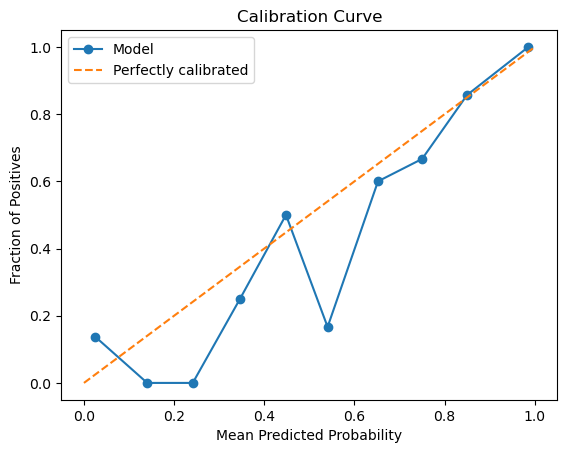

In [364]:
import matplotlib.pyplot as plt

plt.plot(prob_pred, prob_true, marker='o', label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()

In [365]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

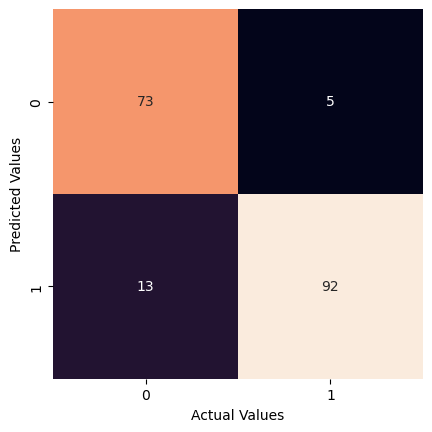

In [366]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [367]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9477411477411477

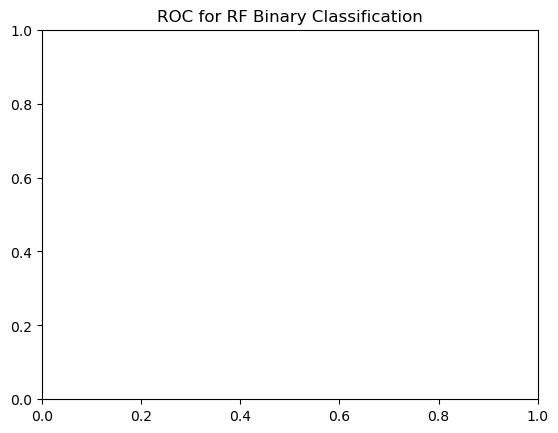

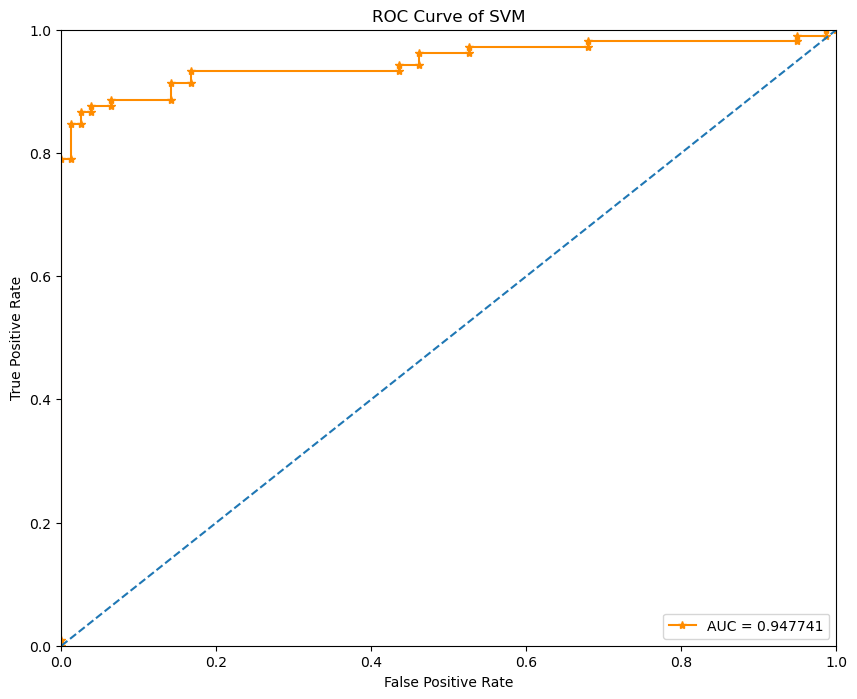

In [368]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of SVM')
plt.show()

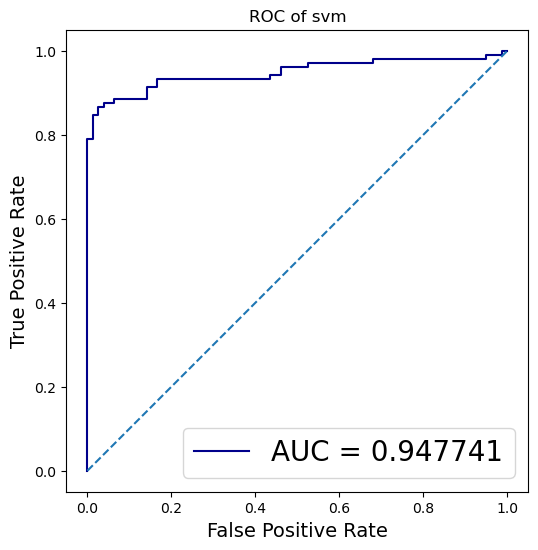

In [369]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of svm')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()


# SHAP

In [370]:
xxx

NameError: name 'xxx' is not defined

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# --- 1) Prepare model and SHAP-ready data ---
best_estimator = grid_search.best_estimator_
print(f"Best estimator type: {type(best_estimator).__name__}")

# Recover feature names with priority:
# 1) Saved names before scaling, 2) DataFrame columns, 3) best_genes, 4) fallback labels
if 'gene_names_selected' in locals() and len(gene_names_selected) == np.asarray(X_train).shape[1]:
    feature_names = list(gene_names_selected)
elif isinstance(X_train, pd.DataFrame):
    feature_names = X_train.columns.tolist()
elif 'best_genes' in locals() and len(best_genes) >= np.asarray(X_train).shape[1]:
    feature_names = list(best_genes[:np.asarray(X_train).shape[1]])
else:
    feature_names = [f"Gene_{i}" for i in range(np.asarray(X_train).shape[1])]

X_train_shap = pd.DataFrame(np.asarray(X_train), columns=feature_names)
X_test_shap = pd.DataFrame(np.asarray(X_test), columns=feature_names)

# Use a subset for speed/stability with KernelExplainer
n_background = min(100, len(X_train_shap))
n_explain = min(80, len(X_test_shap))
background = shap.sample(X_train_shap, n_background, random_state=42)
X_explain = shap.sample(X_test_shap, n_explain, random_state=42)

# --- 2) Build SHAP explainer ---
# For SVC with non-linear kernels, KernelExplainer is the most robust choice.
def predict_pos_class(data):
    return best_estimator.predict_proba(data)[:, 1]

explainer = shap.KernelExplainer(predict_pos_class, background)
print("Calculating SHAP values... (this can take a while)")
shap_values = explainer.shap_values(X_explain, nsamples=200)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    # Older SHAP can return [class0, class1]
    shap_matrix = np.asarray(shap_values[1])
else:
    shap_matrix = np.asarray(shap_values)
    if shap_matrix.ndim == 3:
        # (samples, features, classes) -> positive class
        shap_matrix = shap_matrix[:, :, 1]

print("SHAP matrix shape:", shap_matrix.shape)

Best estimator type: SVC
Calculating SHAP values... (this can take a while)


  0%|          | 0/80 [00:00<?, ?it/s]

SHAP matrix shape: (80, 206)


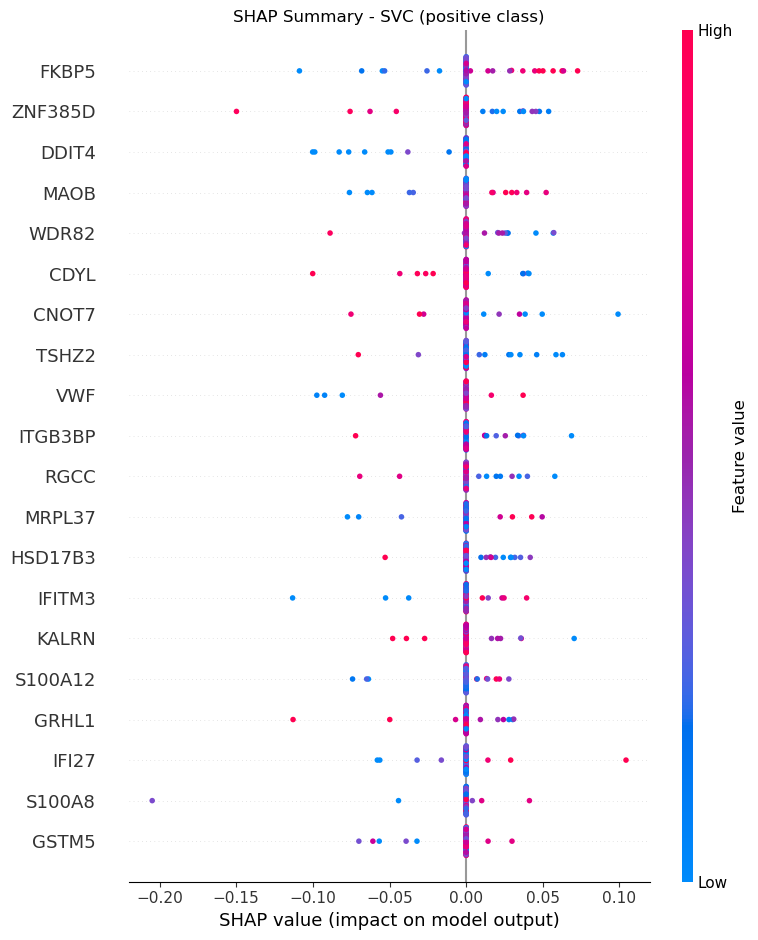

Top 10 Gene Biomarkers:
        Gene  SHAP_Abs_Mean
75     FKBP5       0.010686
77   ZNF385D       0.008816
105    DDIT4       0.007175
12      MAOB       0.006101
103    WDR82       0.005079
44      CDYL       0.004914
181    CNOT7       0.004852
76     TSHZ2       0.004772
69       VWF       0.004751
6    ITGB3BP       0.004576


In [ ]:
# --- 3) Plot SHAP summary ---
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_matrix,
    features=X_explain,
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Summary - {type(best_estimator).__name__} (positive class)")
plt.tight_layout()
plot_name = f"shap_summary_{type(best_estimator).__name__}.png"
# plt.savefig(plot_name, bbox_inches='tight', dpi=300)
plt.show()

# --- 4) Export ranked biomarkers ---
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    'Gene': feature_names,
    'SHAP_Abs_Mean': mean_abs_shap
}).sort_values(by='SHAP_Abs_Mean', ascending=False)

print("Top 10 Gene Biomarkers:")
print(importance_df.head(10))


In [ ]:

importance_df.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\SHAP_svm.csv", index=False)
print(f"Saved SHAP plot to: {plot_name}")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder

# ============================================================
# Chuẩn bị dữ liệu
# ============================================================
X_all = np.vstack([np.asarray(X_train), np.asarray(X_test)])
y_all = np.concatenate([np.asarray(y_train), np.asarray(y_test)])
split_label = (["Train"] * len(X_train)) + (["Test"] * len(X_test))

le = LabelEncoder()
y_encoded = le.fit_transform(y_all)
class_names = le.classes_

# Bảng màu rõ ràng
CLASS_COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
                "#8172B2", "#937860", "#DA8BC3", "#8C8C8C"]
colors = [CLASS_COLORS[i % len(CLASS_COLORS)] for i in y_encoded]

# ============================================================
# HÀM VẼ CHUNG
# ============================================================
def plot_embedding(embedding, title, filename, split_label=None):
    fig, axes = plt.subplots(1, 2 if split_label else 1,
                             figsize=(14, 6) if split_label else (8, 6))
    if split_label is None:
        axes = [axes, None]

    # --- Plot 1: tô màu theo CLASS ---
    ax = axes[0]
    for i, cls in enumerate(class_names):
        mask = (y_encoded == i)
        ax.scatter(embedding[mask, 0], embedding[mask, 1],
                   c=CLASS_COLORS[i % len(CLASS_COLORS)],
                   label=str(cls), alpha=0.75, s=25, edgecolors='none')
    ax.set_title(f"{title}\n(màu = class)", fontsize=12)
    ax.set_xlabel("Dim 1"); ax.set_ylabel("Dim 2")
    ax.legend(title="Class", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

    # --- Plot 2: tô màu theo TRAIN/TEST ---
    if split_label and axes[1] is not None:
        ax2 = axes[1]
        split_colors = {"Train": "#2196F3", "Test": "#FF5722"}
        for split in ["Train", "Test"]:
            mask = np.array(split_label) == split
            ax2.scatter(embedding[mask, 0], embedding[mask, 1],
                        c=split_colors[split], label=split,
                        alpha=0.6, s=25, edgecolors='none')
        ax2.set_title(f"{title}\n(màu = Train/Test split)", fontsize=12)
        ax2.set_xlabel("Dim 1"); ax2.set_ylabel("Dim 2")
        ax2.legend(title="Split", fontsize=9)
        ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {filename}")

# t_SNE

In [ ]:
# ============================================================
# t-SNE
# ============================================================
print("Running t-SNE...")
tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(X_all) // 4),  # tự động điều chỉnh
    # n_iter=1000,
    random_state=42,
    learning_rate='auto',
    init='pca'
)
tsne_embedding = tsne.fit_transform(X_all)
print(f"t-SNE done. KL divergence: {tsne.kl_divergence_:.4f}")

plot_embedding(
    tsne_embedding,
    title="t-SNE — Gene Expression Feature Space",
    filename=r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\tsne_visualization.png",
    split_label=split_label
)

In [ ]:

plot_embedding(
    tsne_embedding,
    title="t-SNE — Gene Expression Feature Space",
    filename=r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\tsne_visualization.png",
    split_label=split_label
)

# UMAP

In [ ]:
# ============================================================
# UMAP  (pip install umap-learn)
# ============================================================
try:
    import umap
    print("Running UMAP...")
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=min(15, len(X_all) // 5),
        min_dist=0.1,
        metric='euclidean',
        random_state=42
    )
    umap_embedding = reducer.fit_transform(X_all)

    plot_embedding(
        umap_embedding,
        title="UMAP — Gene Expression Feature Space",
        filename=r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\umap_visualization.png",
        split_label=split_label
    )
except ImportError:
    print("UMAP chưa cài. Chạy: pip install umap-learn")



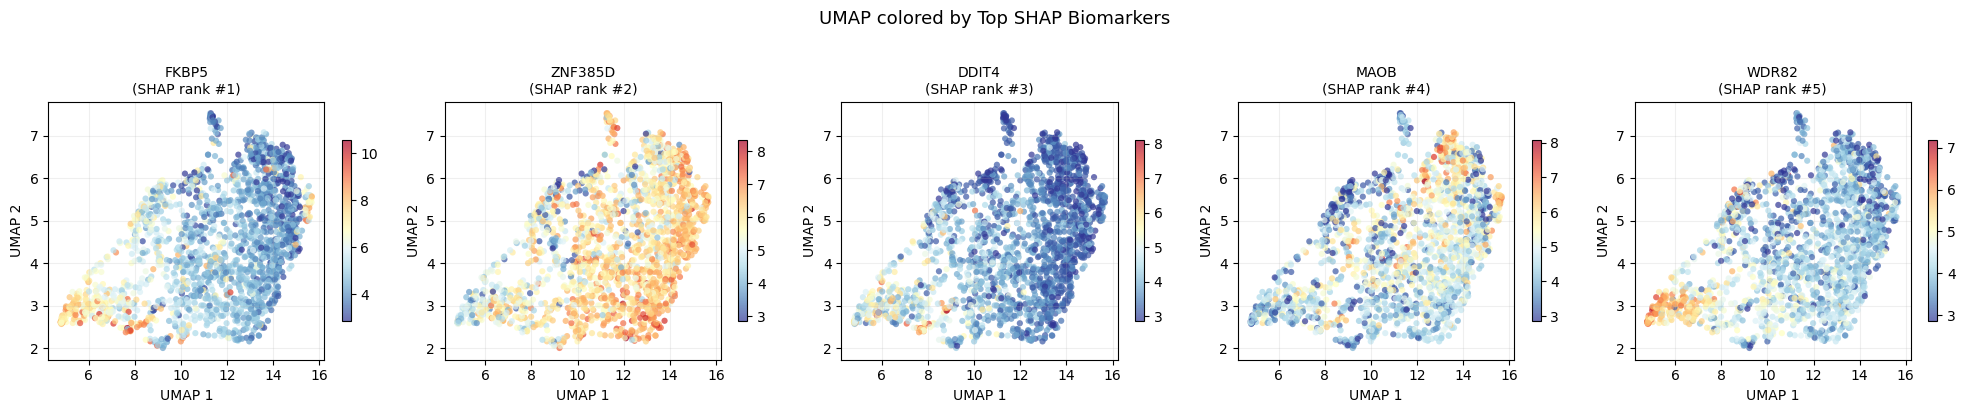

UMAP + SHAP highlight saved.


In [ ]:
# ============================================================
# BONUS: Vẽ UMAP + Top SHAP genes được highlight
# ============================================================
# (Chạy sau khi đã có shap_matrix và importance_df từ bước trước)
try:
    top_n = 5
    top_genes = importance_df['Gene'].head(top_n).tolist()
    top_idx = [feature_names.index(g) for g in top_genes if g in feature_names]

    fig, axes = plt.subplots(1, top_n, figsize=(4 * top_n, 4))
    for ax, gene, idx in zip(axes, top_genes, top_idx):
        gene_vals = X_all[:, idx]
        sc = ax.scatter(umap_embedding[:, 0], umap_embedding[:, 1],
                        c=gene_vals, cmap='RdYlBu_r',
                        alpha=0.7, s=20, edgecolors='none')
        plt.colorbar(sc, ax=ax, shrink=0.7)
        ax.set_title(f"{gene}\n(SHAP rank #{top_genes.index(gene)+1})", fontsize=10)
        ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
        ax.grid(True, alpha=0.2)

    plt.suptitle("UMAP colored by Top SHAP Biomarkers", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\umap_shap_genes.png",
                dpi=300, bbox_inches='tight')
    plt.show()
    print("UMAP + SHAP highlight saved.")
except Exception as e:
    print(f"Bỏ qua UMAP+SHAP plot: {e}")

# UMAP b4 and after

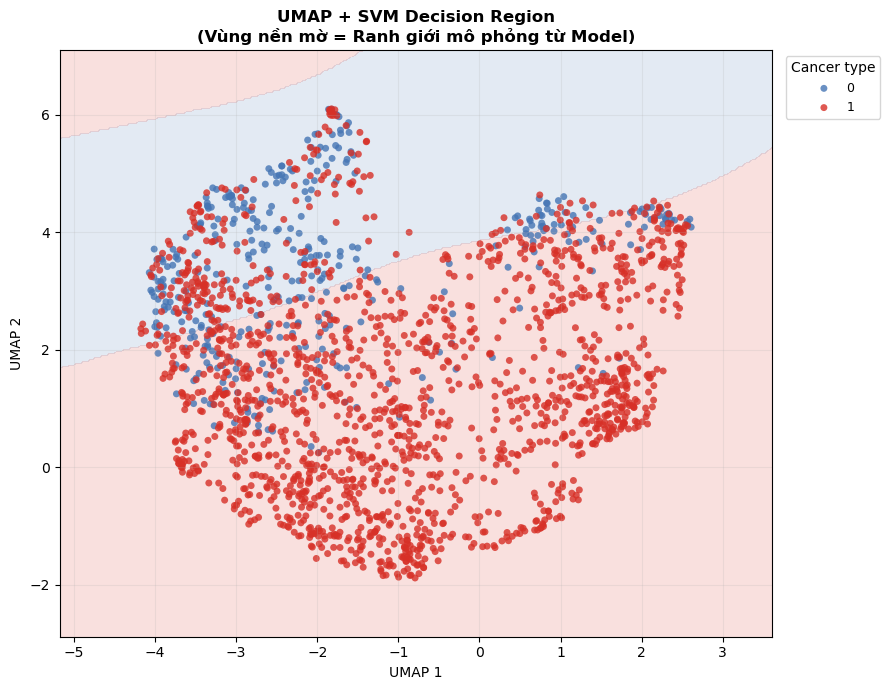

Đã lưu ảnh Decision Region mới!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder

# ============================================================
# Chuẩn bị dữ liệu
# ============================================================
X_all = np.vstack([np.asarray(X_train), np.asarray(X_test)])
y_all = np.concatenate([np.asarray(y_train), np.asarray(y_test)])

# Lấy predicted labels từ model
y_pred_train = best_estimator.predict(np.asarray(X_train))
y_pred_test  = best_estimator.predict(np.asarray(X_test))
y_pred_all   = np.concatenate([y_pred_train, y_pred_test])

le = LabelEncoder()
y_true_enc = le.fit_transform(y_all)
y_pred_enc = le.transform(y_pred_all)
class_names = le.classes_

COLORS = ["#4575b4", "#d73027", "#1D9E75", "#984ea3",
          "#ff7f00", "#a65628", "#f781bf", "#999999"]

# ============================================================
# Tính UMAP 1 lần dùng cho cả 2 panel
# ============================================================
import umap
print("Running UMAP...")
reducer = umap.UMAP(n_components=2, n_neighbors=15,
                    min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(X_all)

# ============================================================
# Vẽ Before vs After
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("UMAP: Before vs After Model Classification",
             fontsize=15, fontweight='bold', y=1.01)

# --- BEFORE: tô màu theo TRUE LABEL (raw clusters) ---
ax = axes[0]
for i, cls in enumerate(class_names):
    mask = (y_true_enc == i)
    ax.scatter(embedding[mask, 0], embedding[mask, 1],
               c=COLORS[i % len(COLORS)],
               label=str(cls), alpha=0.6, s=30, edgecolors='none')

ax.set_title("BEFORE\n(true cancer type — thực tế)", fontsize=12, fontweight='bold')
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
ax.legend(title="Cancer type", bbox_to_anchor=(1.01, 1),
          loc='upper left', fontsize=9)
ax.grid(True, alpha=0.2)
ax.text(0.02, 0.02,
        "Câu hỏi: model có học được\ncác cluster này không?",
        transform=ax.transAxes, fontsize=9,
        color='gray', va='bottom',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

# --- AFTER: tô màu theo PREDICTED LABEL ---
ax2 = axes[1]

# Xác định đúng/sai để vẽ thêm marker
correct = (y_pred_enc == y_true_enc)

for i, cls in enumerate(class_names):
    mask_correct = (y_pred_enc == i) & correct
    mask_wrong   = (y_pred_enc == i) & ~correct

    # Đúng: chấm tròn bình thường
    ax2.scatter(embedding[mask_correct, 0], embedding[mask_correct, 1],
                c=COLORS[i % len(COLORS)],
                label=str(cls), alpha=0.75, s=30, edgecolors='none')

    # Sai: chấm có viền đen để dễ thấy
    ax2.scatter(embedding[mask_wrong, 0], embedding[mask_wrong, 1],
                c=COLORS[i % len(COLORS)],
                alpha=0.9, s=60, edgecolors='black', linewidths=1.2,
                marker='X')

ax2.set_title("AFTER\n(predicted by model — dự đoán)", fontsize=12, fontweight='bold')
ax2.set_xlabel("UMAP 1"); ax2.set_ylabel("UMAP 2")
ax2.legend(title="Predicted class", bbox_to_anchor=(1.01, 1),
           loc='upper left', fontsize=9)
ax2.grid(True, alpha=0.2)

# Chú thích đúng/sai
from matplotlib.lines import Line2D
legend_extra = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
           markersize=8, label=f'Predicted correctly ({correct.sum()})'),
    Line2D([0], [0], marker='X', color='w', markerfacecolor='gray',
           markeredgecolor='black', markersize=8,
           label=f'Misclassified ({(~correct).sum()})'),
]
ax2.legend(handles=legend_extra, loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\Umap b4 aff\umap_before_after.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("Saved!")

# ============================================================
# BONUS: Vẽ thêm decision boundary overlay (tùy chọn)
# ============================================================
# Tô vùng nền theo predicted class để thấy "ranh giới" của model
fig2, ax3 = plt.subplots(figsize=(9, 7))

# Tạo lưới điểm phủ toàn bộ UMAP space
x_min, x_max = embedding[:,0].min()-1, embedding[:,0].max()+1
y_min, y_max = embedding[:,1].min()-1, embedding[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict trên lưới (dùng UMAP space → cần inverse transform nếu có)
# Cách đơn giản: dùng KNN trên embedding để tạo background
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(embedding, y_true_enc)
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Vẽ vùng nền mờ
for i in range(len(class_names)):
    ax3.contourf(xx, yy, (Z == i).astype(float),
                 levels=[0.5, 1.5],
                 colors=[COLORS[i % len(COLORS)]],
                 alpha=0.12)

# Vẽ điểm thực tế
for i, cls in enumerate(class_names):
    mask = (y_true_enc == i)
    ax3.scatter(embedding[mask, 0], embedding[mask, 1],
                c=COLORS[i % len(COLORS)],
                label=str(cls), alpha=0.8, s=25, edgecolors='none')

ax3.set_title("UMAP + Decision Region\n(vùng màu nền = ranh giới model học được)",
              fontsize=12, fontweight='bold')
ax3.set_xlabel("UMAP 1"); ax3.set_ylabel("UMAP 2")
ax3.legend(title="Cancer type", bbox_to_anchor=(1.01,1),
           loc='upper left', fontsize=9)
ax3.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\Umap b4 aff\umap_decision_region.png",
            dpi=300, bbox_inches='tight')
plt.show()